# Classificando Vinhos com Naive Bayes

Problema

Você foi contratado por uma empresa especializada na produção e análise de vinhos.

O laboratório recebe centenas de amostras diariamente e deseja automatizar a identificação do tipo de vinho utilizando Machine Learning.

Seu objetivo será desenvolver um modelo capaz de classificar corretamente o tipo de vinho analisando apenas suas características químicas.

Para isso, você utilizará o algoritmo Naive Bayes.

Objetivos

Ao concluir este projeto você será capaz de:
* Entender o conceito de probabilidade aplicado ao Machine Learning;
* Conhecer o algoritmo Naive Bayes;
* rabalhar com um dataset do Scikit-learn;
* Treinar um modelo;
* Avaliar seu desempenho;
* Fazer previsões para novas amostras.

# Conhecendo o Dataset

O dataset Wine está disponível no próprio Scikit-learn.

Carregue o conjunto de dados.

In [34]:
from sklearn.datasets import load_wine

wine = load_wine()

Transforme o dataset em um DataFrame do Pandas.

O DataFrame deverá possuir as colunas:

* todas as características do vinho;
* uma coluna chamada classe.

In [35]:
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

df["classe"] = wine.target

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,classe
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Responda:

1. Quantas linhas existem?
2. Quantas colunas?
3. Existem valores ausentes?

Utilize:
* df.shape
* df.info()
* df.describe()

In [43]:
print("Shape do DataFrame (linhas, colunas):")
print(df.shape)

print("\nInformações do DataFrame:")
df.info()

print("\nDescrição estatística do DataFrame:")
print(df.describe())

Shape do DataFrame (linhas, colunas):
(178, 14)

Informações do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    fl

1. Quantas linhas existem?

Existem 178 linhas no DataFrame.

2. Quantas colunas?

Existem 14 colunas no DataFrame.

3. Existem valores ausentes?

Não, não existem valores ausentes. Todas as colunas possuem 178 valores não-nulos, o que corresponde ao número total de linhas.



---



# Entendendo os Dados

Responda:

1. Quantos tipos de vinho existem?
2. Quantas amostras existem para cada tipo?

Dica:

df["classe"].value_counts()

In [45]:
df['classe'].value_counts()

,count
classe,
1,71
0,59
2,48


1. Quantos tipos de vinho existem?

Existem 3 tipos diferentes de vinho (representados pelas classes 0, 1 e 2).

2. Quantas amostras existem para cada tipo?

* Para a classe 1, existem 71 amostras.
* Para a classe 0, existem 59 amostras.
* Para a classe 2, existem 48 amostras



---



# Visualização

Construa um Histograma para coluna 'alcohol'

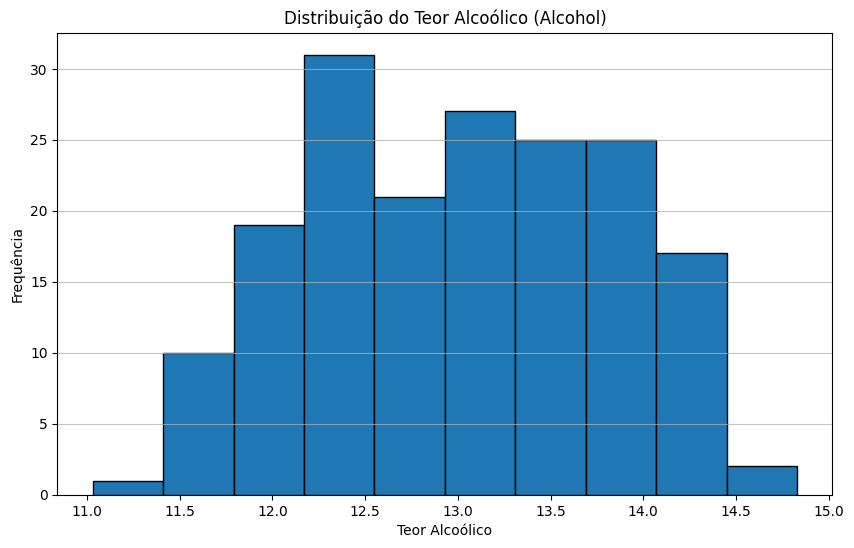

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['alcohol'], bins=10, edgecolor='black')
plt.title('Distribuição do Teor Alcoólico (Alcohol)')
plt.xlabel('Teor Alcoólico')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.75)
plt.show()



---



# Preparando os Dados

Crie:

X

contendo:

* todas as características químicas.

In [47]:
X = df.drop('classe', axis=1)
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Crie:

y

contendo:

* classe

In [48]:
y = df['classe']
y.head()

,classe
0,0
1,0
2,0
3,0
4,0


# Separando Treino e Teste

Utilize:

train_test_split()

com:

* 30% para teste;
* random_state=42.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Treinando o Modelo

Utilize:

from sklearn.naive_bayes import GaussianNB

modelo = GaussianNB()


In [52]:
from sklearn.naive_bayes import GaussianNB

modelo = GaussianNB()

modelo.fit(X_train, y_train)

GaussianNB()

In [54]:
y_pred = modelo.predict(X_test)
print("Primeiras 5 previsões:")
print(y_pred[:5])

Primeiras 5 previsões:
[0 0 2 0 1]


# Fazendo Previsões

Faça previsões utilizando:

modelo.predict(X_test)

In [53]:
y_pred = modelo.predict(X_test)



---



# Avaliando

Mostre:

* Accuracy
* Matriz de Confusão
* Classification Report

In [55]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)
print(f"Taxa de acertos (Accuracy): {accuracy:.2f}\n")

print("Matriz de Confusão:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nRelatório de Classificação:")
report = classification_report(y_test, y_pred)
print(report)

Taxa de acertos (Accuracy): 1.00

Matriz de Confusão:
[[19  0  0]
 [ 0 21  0]
 [ 0  0 14]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00        14

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



# Analise os resultados.

Responda:

1. O modelo apresentou uma boa Accuracy?
   *   Sim, o modelo apresentou uma **Accuracy perfeita de 1.00**, o que é excelente.
2. Houve muitas classificações incorretas?
   *   Não, não houve **nenhuma classificação incorreta**. A matriz de confusão mostra 0 erros para todas as classes.
3. Qual espécie foi mais fácil de identificar?
   *   Todas as espécies foram igualmente fáceis de identificar, pois o modelo classificou **todas as amostras corretamente**.
4. Qual espécie apresentou mais erros?
   *   Nenhuma espécie apresentou erros.



---



# Fazendo Novas Previsões

O laboratório recebeu um novo vinho.

| Característica       | Valor |
| -------------------- | ----- |
| Alcohol              | 13.20 |
| Malic acid           | 1.78  |
| Ash                  | 2.14  |
| Alcalinity of ash    | 11.2  |
| Magnesium            | 100   |
| Total phenols        | 2.65  |
| Flavanoids           | 2.76  |
| Nonflavanoid phenols | 0.26  |
| Proanthocyanins      | 1.28  |
| Color intensity      | 4.38  |
| Hue                  | 1.05  |
| OD280/OD315          | 3.40  |
| Proline              | 1050  |


utilize:

modelo.predict([nova_amostra])

In [56]:
import numpy as np

nova_amostra = np.array([
    13.20,  # Alcohol
    1.78,   # Malic acid
    2.14,   # Ash
    11.2,   # Alcalinity of ash
    100.0,  # Magnesium
    2.65,   # Total phenols
    2.76,   # Flavanoids
    0.26,   # Nonflavanoid phenols
    1.28,   # Proanthocyanins
    4.38,   # Color intensity
    1.05,   # Hue
    3.40,   # OD280/OD315
    1050.0  # Proline
]).reshape(1, -1) # Reshape for a single sample

previsao = modelo.predict(nova_amostra)

print(f"A previsão para o novo vinho é: Classe {previsao[0]}")

A previsão para o novo vinho é: Classe 0


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(




---



Desafio

Treine também usando:

KNN

In [57]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Inicializa e treina o modelo KNN
modelo_knn = KNeighborsClassifier(n_neighbors=5) # Você pode ajustar o número de vizinhos (n_neighbors)
modelo_knn.fit(X_train, y_train)

# Faz previsões com o modelo KNN
y_pred_knn = modelo_knn.predict(X_test)

# Avalia o desempenho do modelo KNN
print("\n--- Avaliação do Modelo KNN ---")
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print(f"Taxa de acertos (Accuracy) KNN: {accuracy_knn:.2f}\n")

print("Matriz de Confusão KNN:")
cm_knn = confusion_matrix(y_test, y_pred_knn)
print(cm_knn)

print("\nRelatório de Classificação KNN:")
report_knn = classification_report(y_test, y_pred_knn)
print(report_knn)


--- Avaliação do Modelo KNN ---
Taxa de acertos (Accuracy) KNN: 0.74

Matriz de Confusão KNN:
[[17  0  2]
 [ 1 15  5]
 [ 1  5  8]]

Relatório de Classificação KNN:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        19
           1       0.75      0.71      0.73        21
           2       0.53      0.57      0.55        14

    accuracy                           0.74        54
   macro avg       0.73      0.73      0.73        54
weighted avg       0.74      0.74      0.74        54





---



Depois responda:

1. Qual algoritmo apresentou melhor desempenho?
   *   O algoritmo **Naive Bayes** apresentou um desempenho significativamente melhor, com uma acurácia de 1.00 (100%). O KNN alcançou uma acurácia de 0.74 (74%).

2. O Naive Bayes foi o melhor para esse dataset?
   *   Sim, para este conjunto de dados e especificamente para esta divisão de treino/teste, o **Naive Bayes foi o melhor** algoritmo, atingindo uma classificação perfeita.

3. Em quais situações você escolheria utilizar o Naive Bayes?
   *   Eu escolheria utilizar o Naive Bayes em situações onde a suposição de independência condicional entre as características (dado a classe) é razoável, ou quando o dataset é pequeno, pois ele é computacionalmente eficiente e pode apresentar bom desempenho. É particularmente útil para problemas de classificação de texto (como filtros de spam) e em cenários onde a velocidade de treinamento e predição é crítica.